In [7]:
import xml.etree.ElementTree as ET
import pandas as pd
from tqdm import tqdm

def parse_xml_annotations(label_folder):

    records = []

    for xml_file in tqdm(list(label_folder.glob("*.xml"))):

        try:
            root = ET.parse(xml_file).getroot()

            filename = root.findtext("filename")

            for obj in root.findall("object"):

                box = obj.find("bndbox")

                records.append({
                    "filename": filename,
                    "label_file": xml_file.name,
                    "class": obj.findtext("name"),
                    "xmin": int(box.findtext("xmin")),
                    "ymin": int(box.findtext("ymin")),
                    "xmax": int(box.findtext("xmax")),
                    "ymax": int(box.findtext("ymax"))
                })

        except Exception as e:
            print(f"Error in {xml_file.name}: {e}")

    return pd.DataFrame(records)


pb_annotations = parse_xml_annotations(
    Path(r"D:\Capstone\metal additive manufacturing\data\Original Images and Manual Labels\Original Images and manual labels\PB_label")
)

display(pb_annotations.head(10))

100%|██████████| 1530/1530 [00:00<00:00, 3489.65it/s]


,filename,label_file,class,xmin,ymin,xmax,ymax
0,SI383820211201123521_00009_20211201T125928.564...,SI383820211201123521_00009_20211201T125928.564...,defects,276,725,350,738
1,SI383820211201123521_00009_20211201T125928.564...,SI383820211201123521_00009_20211201T125928.564...,defects,586,745,656,761
2,SI383820211201123521_00009_20211201T125928.564...,SI383820211201123521_00009_20211201T125928.564...,defects,634,723,647,733
3,SI383820211201123521_00009_20211201T125928.564...,SI383820211201123521_00009_20211201T125928.564...,defects,681,728,696,761
4,SI383820211201123521_00009_20211201T125928.564...,SI383820211201123521_00009_20211201T125928.564...,defects,745,726,776,751
5,SI383820211201123521_00009_20211201T125928.564...,SI383820211201123521_00009_20211201T125928.564...,defects,829,722,868,736
6,SI383820211201123521_00011_20211201T130024.623...,SI383820211201123521_00011_20211201T130024.623...,defects,173,740,359,756
7,SI383820211201123521_00011_20211201T130024.623...,SI383820211201123521_00011_20211201T130024.623...,defects,365,721,410,756
8,SI383820211201123521_00011_20211201T130024.623...,SI383820211201123521_00011_20211201T130024.623...,defects,889,716,919,760
9,SI383820211201123521_00011_20211201T130024.623...,SI383820211201123521_00011_20211201T130024.623...,defects,751,720,850,728


In [5]:
print("Total annotated defect boxes:", len(pb_annotations))

print(
    "Unique images with annotations:",
    pb_annotations["filename"].nunique()
)

print("\nDefect class distribution:")
print(pb_annotations["class"].value_counts())

print("\nDefects per image:")
print(
    pb_annotations.groupby("filename")
    .size()
    .describe()
)

NameError: name 'pb_annotations' is not defined

In [6]:
from pathlib import Path

In [8]:
print("Total defect annotations:", len(pb_annotations))
print("Unique annotated images:", pb_annotations["filename"].nunique())

Total defect annotations: 5001
Unique annotated images: 1530


In [9]:
print("TOTAL PB ANNOTATION STATISTICS")
print("-" * 40)

print("Total defect bounding boxes:", len(pb_annotations))

print(
    "Unique images with annotations:",
    pb_annotations["filename"].nunique()
)

print(
    "Total defect classes:",
    pb_annotations["class"].nunique()
)

print("\nDefect class distribution:")
print(pb_annotations["class"].value_counts())

TOTAL PB ANNOTATION STATISTICS
----------------------------------------
Total defect bounding boxes: 5001
Unique images with annotations: 1530
Total defect classes: 1

Defect class distribution:
class
defects    5001
Name: count, dtype: int64


In [10]:
defects_per_image = (
    pb_annotations.groupby("filename")
    .size()
    .reset_index(name="defect_count")
)

display(defects_per_image.head(10))

print("\nSTATISTICS")
print(defects_per_image["defect_count"].describe())

,filename,defect_count
0,SI383820211201123521_00009_20211201T125928.564...,6
1,SI383820211201123521_00011_20211201T130024.623...,4
2,SI383820211201123521_00012_20211201T130037.654...,3
3,SI383820211201123521_00013_20211201T130118.809...,1
4,SI383820211201123521_00014_20211201T130131.811...,1
5,SI383820211201123521_00015_20211201T130212.865...,1
6,SI383820211201123521_00016_20211201T130226.929...,1
7,SI383820211201123521_00017_20211201T130306.976...,1
8,SI383820211201123521_00018_20211201T130320.029...,4
9,SI383820211201123521_00019_20211201T130406.431...,1



STATISTICS
count    1530.000000
mean        3.268627
std         1.949089
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        12.000000
Name: defect_count, dtype: float64


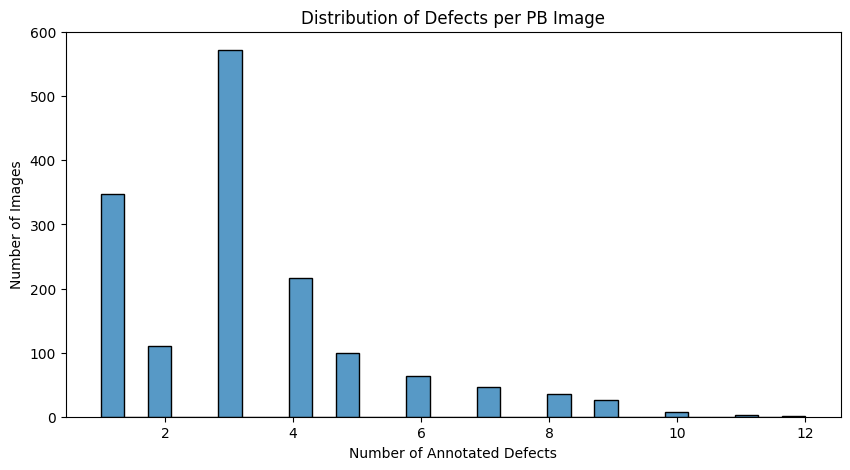

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=defects_per_image,
    x="defect_count",
    bins=30
)

plt.title("Distribution of Defects per PB Image")
plt.xlabel("Number of Annotated Defects")
plt.ylabel("Number of Images")

plt.show()

In [12]:
from PIL import Image
import matplotlib.patches as patches

def visualize_annotated_image(filename):

    image_path = PB_PATH / filename
    image = Image.open(image_path)

    annotations = pb_annotations[
        pb_annotations["filename"] == filename
    ]

    fig, ax = plt.subplots(figsize=(14, 9))

    ax.imshow(image, cmap="gray")

    for _, row in annotations.iterrows():

        rect = patches.Rectangle(
            (row["xmin"], row["ymin"]),
            row["xmax"] - row["xmin"],
            row["ymax"] - row["ymin"],
            linewidth=1.5,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

    ax.set_title(
        f"PB Image: {filename}\n"
        f"Defects: {len(annotations)}"
    )

    ax.axis("off")
    plt.show()

In [13]:

visualize_annotated_image(
    "SI383820211201123521_00009_20211201T125928.564000.jpg"
)

NameError: name 'PB_PATH' is not defined

In [14]:
from pathlib import Path

DATASET_PATH = Path(
    r"D:\Capstone\metal additive manufacturing\data\Original Images and Manual Labels\Original Images and manual labels"
)

PB_PATH = DATASET_PATH / "PB"
OT_PATH = DATASET_PATH / "OT"

PB_LABEL_PATH = DATASET_PATH / "PB_label"
OT_LABEL_PATH = DATASET_PATH / "OT_label"

In [15]:
print("PB folder exists:", PB_PATH.exists())
print("Image exists:", (
    PB_PATH / "SI383820211201123521_00009_20211201T125928.564000.jpg"
).exists())

PB folder exists: True
Image exists: True


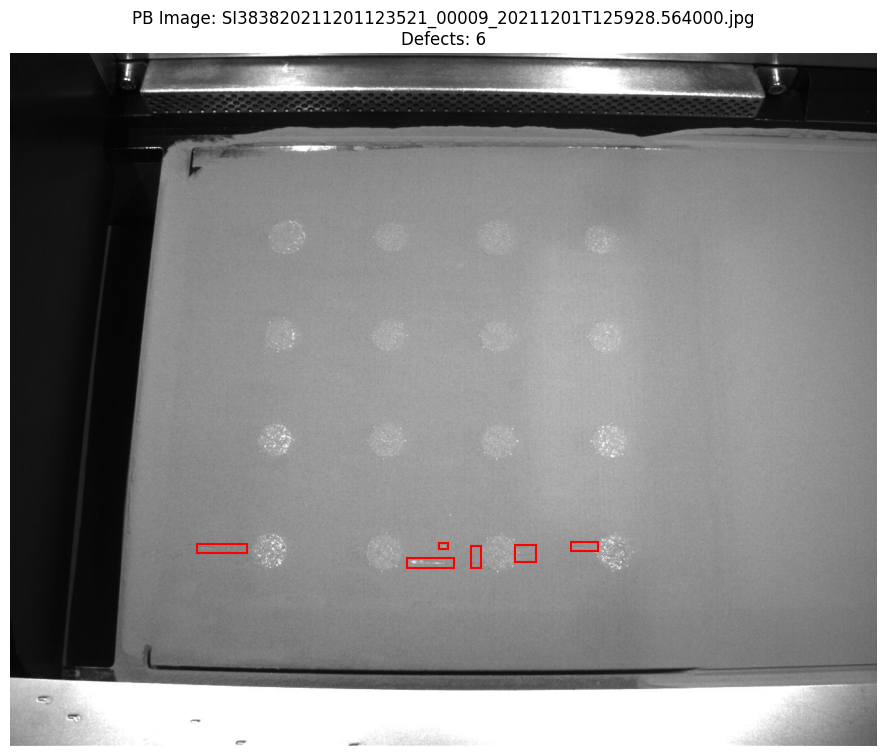

In [16]:
visualize_annotated_image(
    "SI383820211201123521_00009_20211201T125928.564000.jpg"
)

In [17]:
pb_annotations.to_csv(
    "pb_annotations.csv",
    index=False
)